# 02 — Baseline models, métricas e interpretabilidad

Se comparan tres algoritmos de clasificación y un Dummy baseline. La separación se realiza por **distritos completos** para evitar que el mismo distrito aparezca en entrenamiento y prueba.

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score,
    mean_absolute_error, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from src.proyecto_ml import FEATURES_MODELO, crear_preprocesador, localizar_raiz, validar_ausencia_fuga

RAIZ = localizar_raiz()
PROCESSED = RAIZ / "data" / "processed"
FIGURES = RAIZ / "outputs" / "figures"
METRICS = RAIZ / "outputs" / "metrics"
MODELS = RAIZ / "models"
for carpeta in [FIGURES, METRICS, MODELS]: carpeta.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
df = pd.read_csv(PROCESSED / "dataset_analitico_6to_bachillerato.csv")
print("Dataset:", df.shape)

Dataset: (522, 22)


/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Separación agrupada y creación del objetivo

La etiqueta `alta_no_asistencia_6to_bachillerato` representa los registros cuya tasa es igual o superior al percentil 75 del conjunto de entrenamiento. El umbral no se calcula con el conjunto de prueba.

In [2]:
X = df[FEATURES_MODELO].copy()
grupos = df["grupo_geografico"].copy()
validar_ausencia_fuga(X.columns)

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
idx_train, idx_test = next(splitter.split(X, groups=grupos))

umbral = float(df.iloc[idx_train]["tasa_nunca_asistio"].quantile(0.75))
df["alta_no_asistencia_6to_bachillerato"] = (df["tasa_nunca_asistio"] >= umbral).astype(int)
y = df["alta_no_asistencia_6to_bachillerato"]

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
g_train, g_test = grupos.iloc[idx_train], grupos.iloc[idx_test]

assert set(g_train).isdisjoint(set(g_test))
print("Umbral de entrenamiento:", umbral)
print("Entrenamiento:", X_train.shape, "distritos:", g_train.nunique())
print("Prueba:", X_test.shape, "distritos:", g_test.nunique())
print("Proporción positiva train/test:", round(y_train.mean(), 4), round(y_test.mean(), 4))

Umbral de entrenamiento: 0.1216216216216216
Entrenamiento: (417, 3) distritos: 209
Prueba: (105, 3) distritos: 53
Proporción positiva train/test: 0.2518 0.2095


In [3]:
df.to_csv(PROCESSED / "dataset_modelado_6to_bachillerato.csv", index=False, encoding="utf-8-sig")

distribucion = pd.DataFrame({
    "conjunto": ["Entrenamiento", "Prueba"],
    "filas": [len(X_train), len(X_test)],
    "distritos": [g_train.nunique(), g_test.nunique()],
    "positivos": [int(y_train.sum()), int(y_test.sum())],
    "proporcion_positiva": [y_train.mean(), y_test.mean()],
})
distribucion.to_csv(METRICS / "distribucion_train_test.csv", index=False, encoding="utf-8-sig")
distribucion

,conjunto,filas,distritos,positivos,proporcion_positiva
0,Entrenamiento,417,209,105,0.251799
1,Prueba,105,53,22,0.209524


## 2. Modelos baseline y pipelines

Cada pipeline aprende la imputación y el One-Hot Encoding usando solamente entrenamiento. Los predictores seleccionados son **departamento, municipio y nivel educativo aproximado**. Se excluyen las múltiples representaciones redundantes de edad y todos los conteos que construyen la tasa objetivo.

In [4]:
modelos = {
    "Dummy por prior": DummyClassifier(strategy="prior"),
    "Regresión Logística": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
    "Árbol de Decisión": DecisionTreeClassifier(max_depth=5, min_samples_leaf=8, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=220, max_depth=8, min_samples_leaf=4, class_weight="balanced", random_state=42, n_jobs=1),
}

pipelines = {
    nombre: Pipeline([("preprocesador", crear_preprocesador()), ("modelo", modelo)])
    for nombre, modelo in modelos.items()
}

resultados = []
predicciones = {}
probabilidades = {}
for nombre, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    proba = pipeline.predict_proba(X_test)[:, 1]
    predicciones[nombre] = pred
    probabilidades[nombre] = proba
    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "MAE": mean_absolute_error(y_test, pred),
    })

comparacion = pd.DataFrame(resultados).sort_values("F1", ascending=False).reset_index(drop=True)
comparacion.to_csv(METRICS / "comparacion_modelos_test.csv", index=False, encoding="utf-8-sig")
comparacion.round(4)

,Modelo,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,MAE
0,Regresión Logística,0.7333,0.8313,0.4400,1.0000,0.6111,0.8428,0.2667
1,Random Forest,0.7238,0.8253,0.4314,1.0000,0.6027,0.8398,0.2762
2,Árbol de Decisión,0.7143,0.8026,0.4200,0.9545,0.5833,0.8061,0.2857
3,Dummy por prior,0.7905,0.5000,0.0000,0.0000,0.0000,0.5000,0.2095


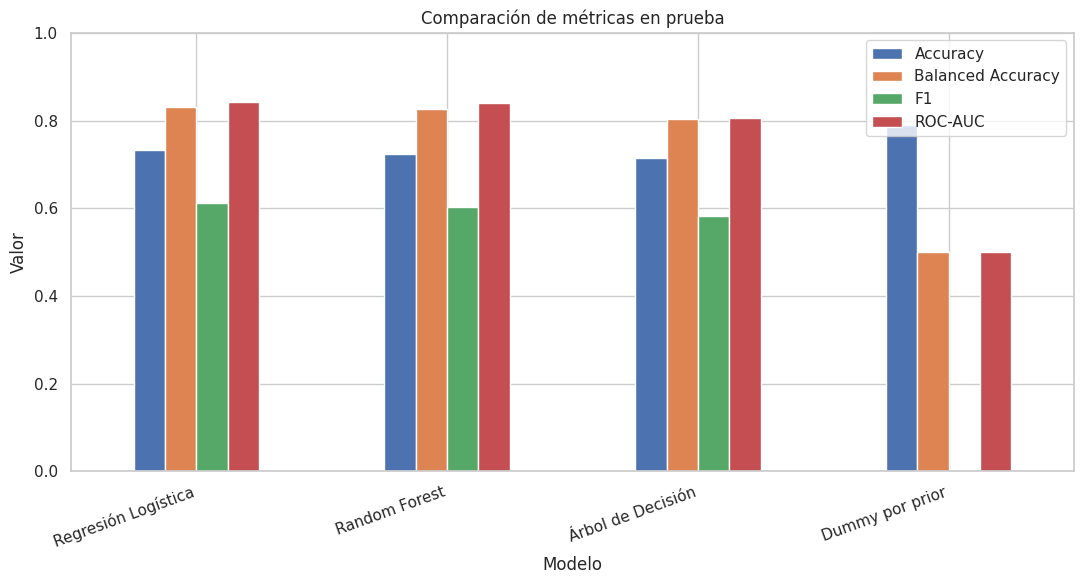

In [5]:
metricas_grafico = comparacion.set_index("Modelo")[["Accuracy", "Balanced Accuracy", "F1", "ROC-AUC"]]
ax = metricas_grafico.plot(kind="bar", figsize=(11, 6))
ax.set_ylim(0, 1)
ax.set_ylabel("Valor")
ax.set_title("Comparación de métricas en prueba")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(FIGURES / "12_comparacion_metricas_modelos.png", dpi=160)
plt.show()

La accuracy del Dummy puede ser alta por el desbalance de clases, pero su F1 y recall son cero. Por ello se priorizan F1, balanced accuracy y ROC-AUC para comparar capacidad de identificar la clase positiva.

## 3. Matrices de confusión y curvas ROC

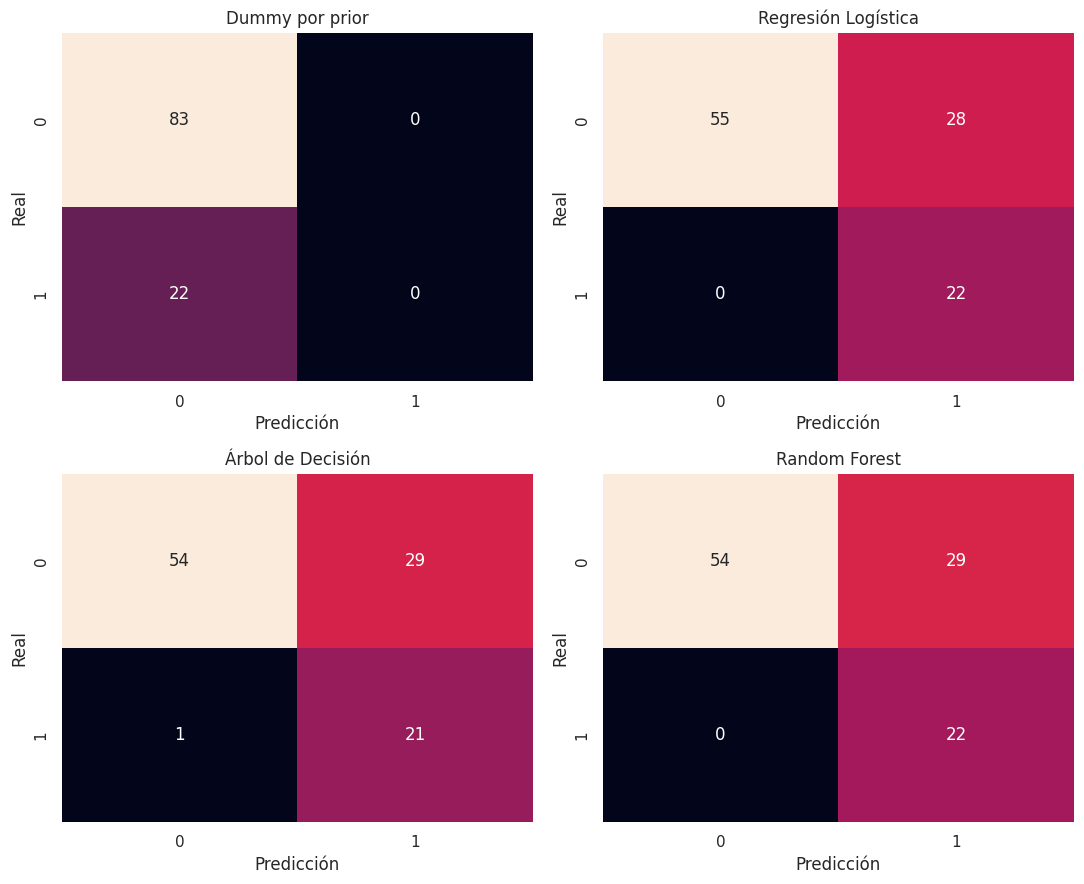

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (nombre, pred) in zip(axes.flatten(), predicciones.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cbar=False, ax=ax)
    ax.set_title(nombre)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Real")
plt.tight_layout()
plt.savefig(FIGURES / "13_matrices_confusion.png", dpi=160)
plt.show()

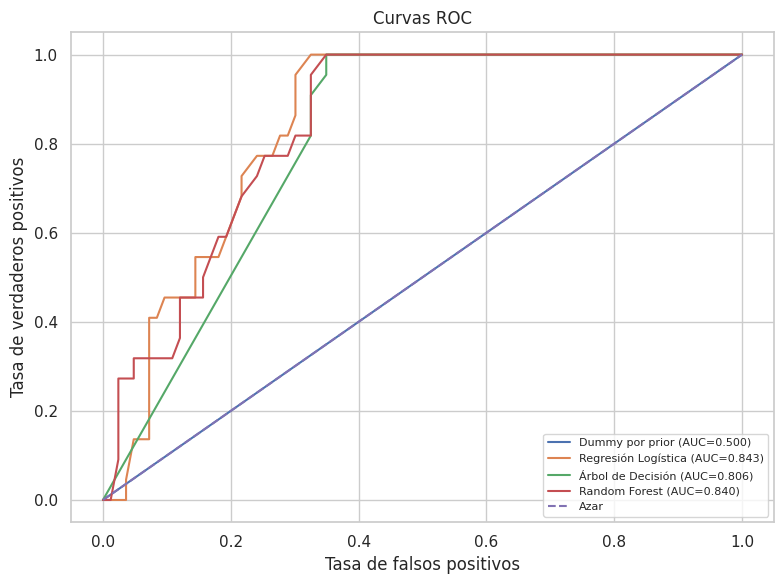

In [7]:
plt.figure(figsize=(8, 6))
for nombre, proba in probabilidades.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{nombre} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Azar")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curvas ROC")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "14_curvas_roc.png", dpi=160)
plt.show()

## 4. Validación cruzada agrupada

La validación se realiza solamente sobre entrenamiento mediante `GroupKFold`, manteniendo separados los distritos.

In [8]:
scoring = {
    "accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy",
    "f1": "f1", "roc_auc": "roc_auc", "neg_mae": "neg_mean_absolute_error",
}
gkf = GroupKFold(n_splits=5)
filas_cv = []
for nombre, pipeline in pipelines.items():
    cv = cross_validate(clone(pipeline), X_train, y_train, groups=g_train, cv=gkf, scoring=scoring, n_jobs=1)
    filas_cv.append({
        "Modelo": nombre,
        "Accuracy media": cv["test_accuracy"].mean(),
        "Accuracy std": cv["test_accuracy"].std(),
        "Balanced Accuracy media": cv["test_balanced_accuracy"].mean(),
        "F1 media": cv["test_f1"].mean(),
        "F1 std": cv["test_f1"].std(),
        "ROC-AUC media": cv["test_roc_auc"].mean(),
        "MAE media": -cv["test_neg_mae"].mean(),
    })
validacion_cv = pd.DataFrame(filas_cv).sort_values("F1 media", ascending=False)
validacion_cv.to_csv(METRICS / "validacion_cruzada_agrupada.csv", index=False, encoding="utf-8-sig")
validacion_cv.round(4)

,Modelo,Accuracy media,Accuracy std,Balanced Accuracy media,F1 media,F1 std,ROC-AUC media,MAE media
3,Random Forest,0.7599,0.0475,0.8273,0.6602,0.0807,0.8352,0.2401
1,Regresión Logística,0.7527,0.0449,0.8137,0.6469,0.0779,0.8239,0.2473
2,Árbol de Decisión,0.7527,0.0438,0.8128,0.6468,0.0852,0.8420,0.2473
0,Dummy por prior,0.7485,0.0536,0.5000,0.0000,0.0000,0.5000,0.2515


## 5. Selección y guardado del modelo

In [9]:
mejor_nombre = comparacion.iloc[0]["Modelo"]
mejor_pipeline = pipelines[mejor_nombre]
joblib.dump(mejor_pipeline, MODELS / "mejor_modelo_6to_bachillerato.joblib")
metadata = {
    "modelo_seleccionado": mejor_nombre,
    "criterio": "Mayor F1 en conjunto de prueba agrupado por distrito",
    "umbral_tasa_entrenamiento": umbral,
    "features": FEATURES_MODELO,
    "grupos_etarios": ["10 a 14 años", "15 a 19 años"],
    "limitacion": "Proxy etario; no identifica grado cursado ni abandono individual",
    "metricas_test": comparacion.iloc[0].to_dict(),
}
with open(MODELS / "metadata_modelo.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)
print("Modelo seleccionado:", mejor_nombre)

Modelo seleccionado: Regresión Logística


## 6. Interpretabilidad básica con SHAP

SHAP se aplica al Random Forest para analizar importancia global, dirección de efectos y un caso local. La explicación describe asociaciones del modelo, no causas.

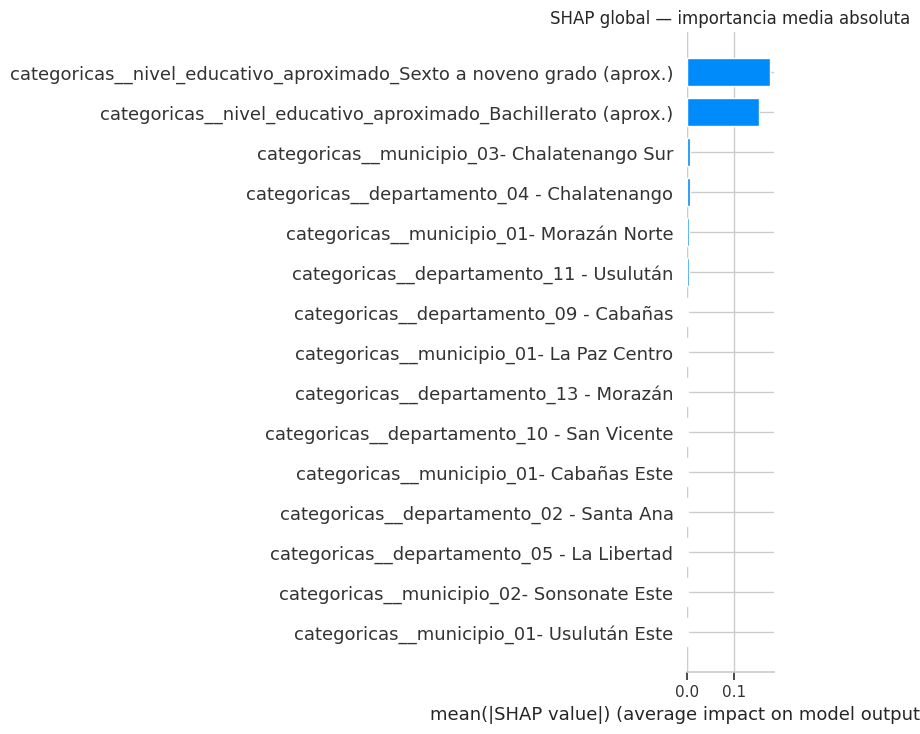

,feature,mean_abs_shap
59,categoricas__nivel_educativo_aproximado_Sexto ...,0.174987
58,categoricas__nivel_educativo_aproximado_Bachil...,0.152944
43,categoricas__municipio_03- Chalatenango Sur,0.007361
3,categoricas__departamento_04 - Chalatenango,0.006762
21,categoricas__municipio_01- Morazán Norte,0.005724
10,categoricas__departamento_11 - Usulután,0.005385
8,categoricas__departamento_09 - Cabañas,0.002946
19,categoricas__municipio_01- La Paz Centro,0.002937
12,categoricas__departamento_13 - Morazán,0.002721
9,categoricas__departamento_10 - San Vicente,0.002718


In [10]:
pipeline_rf = pipelines["Random Forest"]
preprocesador_rf = pipeline_rf.named_steps["preprocesador"]
modelo_rf = pipeline_rf.named_steps["modelo"]

muestra = X_test.sample(n=min(105, len(X_test)), random_state=42)
X_muestra_transformada = preprocesador_rf.transform(muestra)
if hasattr(X_muestra_transformada, "toarray"):
    X_muestra_transformada = X_muestra_transformada.toarray()

nombres_features = preprocesador_rf.get_feature_names_out()
explainer = shap.TreeExplainer(modelo_rf)
explicacion = explainer(X_muestra_transformada)
if explicacion.values.ndim == 3:
    valores_clase_1 = explicacion.values[:, :, 1]
    base_clase_1 = explicacion.base_values[:, 1]
else:
    valores_clase_1 = explicacion.values
    base_clase_1 = explicacion.base_values

importancia_shap = pd.DataFrame({
    "feature": nombres_features,
    "mean_abs_shap": np.abs(valores_clase_1).mean(axis=0),
}).sort_values("mean_abs_shap", ascending=False)
importancia_shap.to_csv(METRICS / "importancia_shap_global.csv", index=False, encoding="utf-8-sig")

plt.figure(figsize=(10, 7))
shap.summary_plot(valores_clase_1, X_muestra_transformada, feature_names=nombres_features,
                  plot_type="bar", max_display=15, show=False)
plt.title("SHAP global — importancia media absoluta")
plt.tight_layout()
plt.savefig(FIGURES / "15_shap_importancia_global.png", dpi=160, bbox_inches="tight")
plt.show()
importancia_shap.head(15)

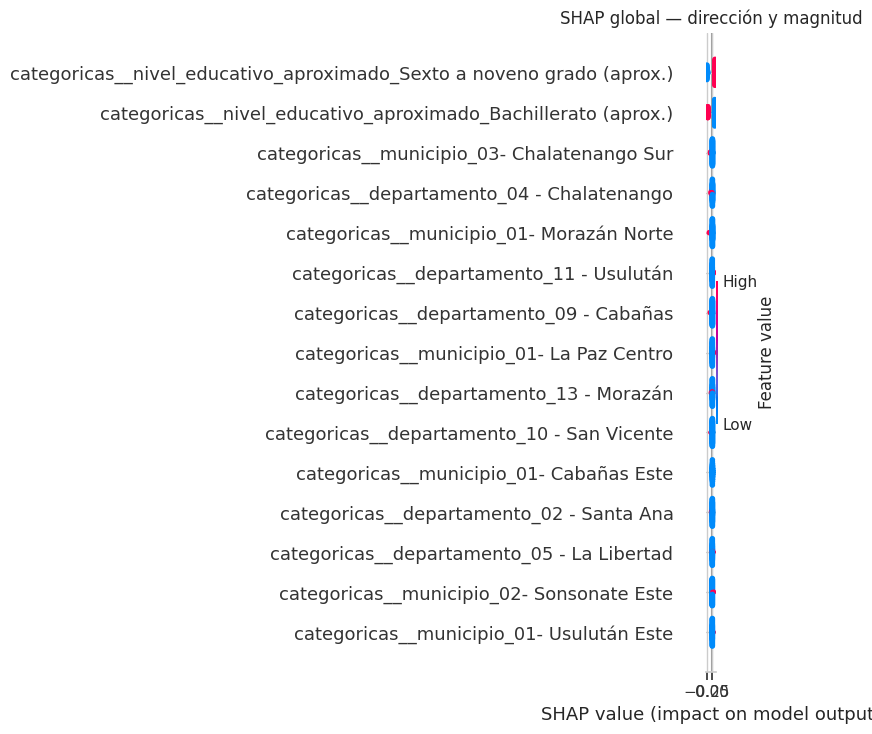

In [11]:
plt.figure(figsize=(10, 7))
shap.summary_plot(valores_clase_1, X_muestra_transformada, feature_names=nombres_features,
                  max_display=15, show=False)
plt.title("SHAP global — dirección y magnitud")
plt.tight_layout()
plt.savefig(FIGURES / "16_shap_beeswarm.png", dpi=160, bbox_inches="tight")
plt.show()

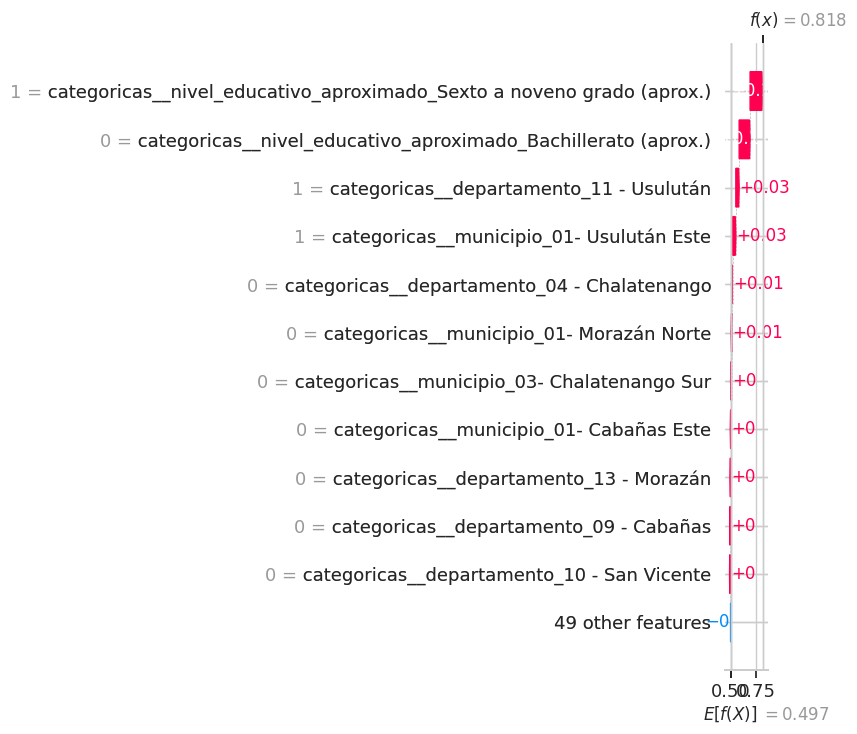

,valor
departamento,11 - Usulután
municipio,01- Usulután Este
nivel_educativo_aproximado,Sexto a noveno grado (aprox.)
probabilidad_estimada,0.81784


In [12]:
proba_muestra = pipeline_rf.predict_proba(muestra)[:, 1]
posicion_local = int(np.argmax(proba_muestra))
exp_local = shap.Explanation(
    values=valores_clase_1[posicion_local],
    base_values=base_clase_1[posicion_local] if np.ndim(base_clase_1) else base_clase_1,
    data=X_muestra_transformada[posicion_local], feature_names=nombres_features,
)
plt.figure(figsize=(10, 7))
shap.plots.waterfall(exp_local, max_display=12, show=False)
plt.tight_layout()
plt.savefig(FIGURES / "17_shap_explicacion_local.png", dpi=160, bbox_inches="tight")
plt.show()

caso_local = muestra.iloc[posicion_local].to_frame("valor")
caso_local.loc["probabilidad_estimada"] = proba_muestra[posicion_local]
caso_local

## Conclusión

Los modelos funcionan como baseline territorial. No predicen el abandono de un estudiante particular. Una clasificación positiva indica semejanza con territorios y grupos etarios que presentan una tasa alta de nunca asistencia según la definición estadística del proyecto.